# 3. 내 고객 이해하기

분석 질문을 **"그래서 판매자는 뭘 해야 하나"**로 바꿔서 답해요.

| 세부 기능 | 질문 | 도구 (`customer_insight`의 topic) |
| --- | --- | --- |
| 3-1 오래 걸려서 vs 약속을 어겨서 | "고객이 뭐에 화가 나?" | `promise` |
| 3-2 지연 일수별 별점 | "하루 늦으면 얼마나 깎여?" | `plot_delay_vs_score` |
| 3-3 지역별 불만 (쓰나미식 비율 barh) | "어느 지역이 불만이 많아?" | `region`, `plot_state_complaints` |
| 3-4 권역별 배송일 (상자그림) | "북동부는 얼마나 걸려?" | `region_days`, `plot_region_days` |
| 3-5 화난 고객은 리뷰를 빨리 쓰나 | | `review_speed` |
| 3-6 리뷰에 날짜를 세는 고객 | | `said_days` |
| 3-7 도착 전에 쓰인 리뷰 | | `before_delivery` |
| 3-8 지역 판매 기회 | "어디에 팔면 좋아?" | `opportunity` |

**실행법 (Colab)**: GitHub 저장소(jc020230/BDA)에서 이 노트북을 Colab으로 열고 위에서부터 실행하면 돼요. 첫 셀이 저장소를 자동으로 내려받아서 `seller_tools.py`와 `preprocessing/` 폴더의 데이터를 찾아요. 노트북끼리는 서로 독립이라 아무거나 먼저 열어도 돼요.

**아래 "챗봇이 이렇게 말할 수 있어요"** 문장은 도구 결과 숫자로 자동으로 만든 예시예요. 실제 챗봇에서는 LLM이 이 결과를 받아 자연스럽게 말해요.

In [1]:
# 준비: 저장소 파일(seller_tools.py, 전처리 데이터)을 찾고, 없으면 GitHub에서 내려받기
import os, sys, json, zipfile, subprocess
IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/jc020230/BDA.git'
DATA_DIRS = ['olist_mart', 'preprocessing', '/content/drive/MyDrive/olist_mart']
has_data = lambda p: os.path.exists(f'{p}/orders_mart.parquet')

# Colab에서 GitHub 노트북만 열면 다른 파일이 없어서, 저장소를 통째로 내려받아 그 폴더로 이동
if not os.path.exists('seller_tools.py'):
    if not os.path.exists('BDA/seller_tools.py'):
        subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, 'BDA'], check=True)
    os.chdir('BDA')
MART_DIR = next((p for p in DATA_DIRS if has_data(p)), None)
if MART_DIR is None:   # 저장소에 데이터가 없으면 zip이나 드라이브에서 찾기
    z = next((p for p in ['olist_mart_v2_github.zip', 'olist_mart_v2.zip', 'olist_mart.zip'] if os.path.exists(p)), None)
    if z: zipfile.ZipFile(z).extractall('.'); MART_DIR = 'olist_mart'
    elif IN_COLAB:
        from google.colab import drive; drive.mount('/content/drive'); MART_DIR = next(p for p in DATA_DIRS if has_data(p))

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from seller_tools import SellerTools, TOOLS, setup_korean_font
setup_korean_font()
st = SellerTools(MART_DIR)
if st.evm_table is None:
    print('⚠️ 전처리 1판 결과예요. 2판을 쓰면 이벤트 배수 표와 도착 전 리뷰 기능까지 쓸 수 있어요.')

def show(result, limit=1500):
    """도구 결과(JSON)를 보기 좋게 출력"""
    text = json.dumps(result, ensure_ascii=False, indent=1)
    print(text if len(text) <= limit else text[:limit] + '\n... (생략)')

DEMO = '2eb70248'                  # 시계·선물, 별점 낮고 발송이 느린 판매자 (앞 8자리만 써도 됨)
BIG = st.ss.orders.idxmax()        # 주문이 가장 많은 판매자
print('도구', len(TOOLS), '개 준비 완료 | 작업 폴더:', os.getcwd(), '| 데이터:', MART_DIR)

도구 23 개 준비 완료 | 작업 폴더: /tmp/repo_asof | 데이터: preprocessing


## 3-1. 고객은 "오래 걸려서" 화날까, "약속을 어겨서" 화날까?

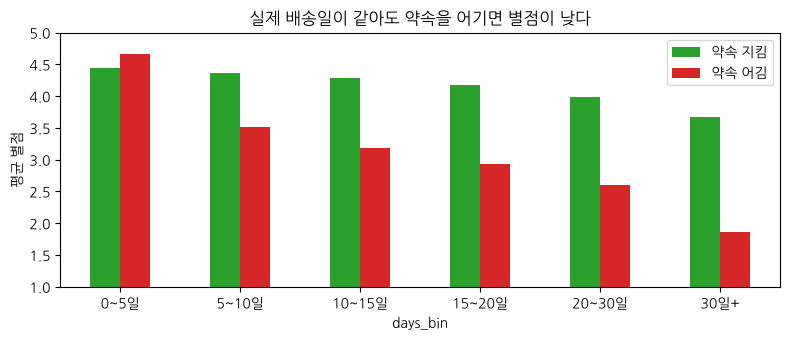

💬 같은 15~20일이 걸려도 약속을 지키면 4.17점, 어기면 2.93점이에요. 내 발송 마감 위반율은 32%(동종 4%)예요. 고객은 오래 걸린 것보다 약속을 어긴 것에 더 화가 나요. 빨리 보내기보다 발송 마감을 지키는 게 먼저예요.


In [2]:
r = st.call('customer_insight', {'seller_id': DEMO, 'topic': 'promise'})
sd = pd.DataFrame(r['market_same_days_kept_vs_broken']).set_index('days_bin').dropna()
ax = sd.rename(columns={'kept': '약속 지킴', 'broken': '약속 어김'}).plot(kind='bar', rot=0, figsize=(8, 3.5), color=['tab:green', 'tab:red'])
ax.set_ylim(1, 5); ax.set_title('실제 배송일이 같아도 약속을 어기면 별점이 낮다'); ax.set_ylabel('평균 별점'); plt.tight_layout(); plt.show()
row = sd.loc['15~20일']
print('💬', f"같은 15~20일이 걸려도 약속을 지키면 {row.kept:.2f}점, 어기면 {row.broken:.2f}점이에요. 내 발송 마감 위반율은 {r['my_ship_late_rate']:.0%}(동종 {r['peer_ship_late_rate']:.0%})예요. {r['advice']}")

## 3-2. 지연 일수별 별점

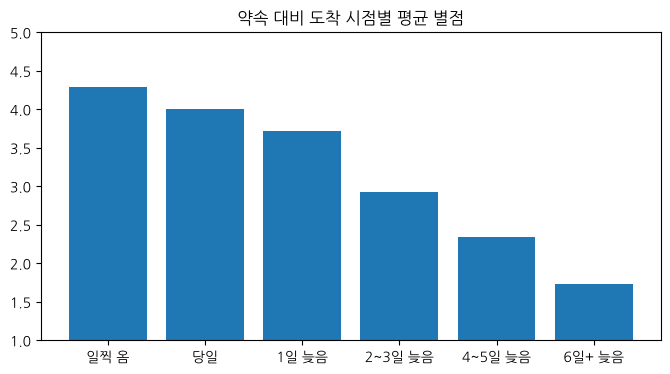

💬 하루 늦으면 3.72점, 2~3일 늦으면 2.93점, 6일 이상이면 1.73점이에요. 2~3일이 고비예요.


In [3]:
st.plot('plot_delay_vs_score'); plt.show()
t = pd.DataFrame(st.summ['delay_vs_score']).set_index('delay_bin')
print('💬', f"하루 늦으면 {t.loc['1일 늦음', 'mean_score']:.2f}점, 2~3일 늦으면 {t.loc['2~3일 늦음', 'mean_score']:.2f}점, 6일 이상이면 {t.loc['6일+ 늦음', 'mean_score']:.2f}점이에요. 2~3일이 고비예요.")

## 3-3. 어느 지역 고객이 가장 불만이 많을까? (쓰나미식 비율 barh)
5장의 쓰나미 비율 그래프와 같은 방법이에요: 주별 별점 구성비(행 합 1)를 1~2점 비율 순으로 정렬해 상위 10개를 뒤집어 쌓은 가로 막대.

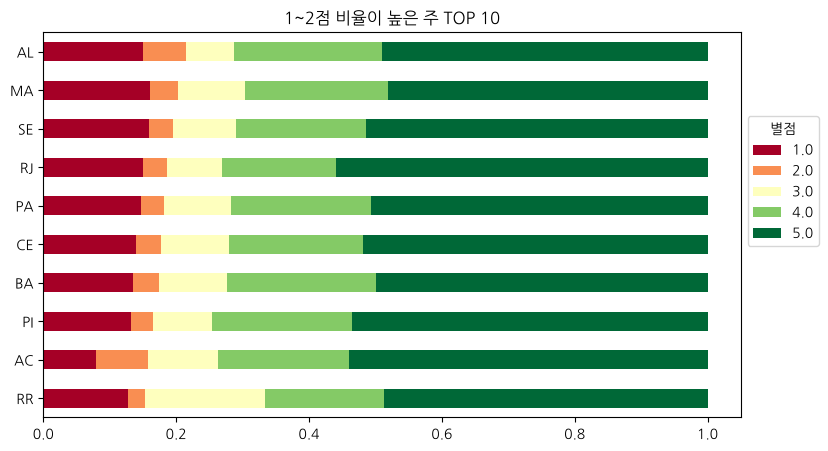

{
 "topic": "region",
 "by_region": [
  {
   "customer_region": "남동부",
   "my_orders": 1296,
   "my_late_rate": 0.0895,
   "my_low_rate": 0.1829,
   "my_order_share": 0.7517,
   "median_days": 8.852,
   "market_late_rate": 0.062,
   "market_low_rate": 0.1249
  },
  {
   "customer_region": "남부",
   "my_orders": 212,
   "my_late_rate": 0.1085,
   "my_low_rate": 0.1887,
   "my_order_share": 0.123,
   "median_days": 12.204,
   "market_late_rate": 0.06,
   "market_low_rate": 0.1201
  },
  {
   "customer_region": "북동부",
   "my_orders": 113,
   "my_late_rate": 0.177,
   "my_low_rate": 0.2455,
   "my_order_share": 0.0655,
   "median_days": 17.374,
   "market_late_rate": 0.128,
   "market_low_rate": 0.1709
  },
  {
   "customer_region": "북부",
   "my_orders": 16,
   "my_late_rate": 0.0625,
   "my_low_rate": 0.125,
   "my_order_share": 0.0093,
   "median_days": 20.168,
   "market_late_rate": 0.086,
   "market_low_rate": 0.1544
  },
  {
   "customer_region": "중서부",
   "my_orders": 87,
   "my_late_

In [4]:
st.plot('plot_state_complaints'); plt.show()
r = st.call('customer_insight', {'seller_id': BIG, 'topic': 'region'})
show(r, 1800)
w = r['market_worst_states']
print('💬', f"1~2점 비율은 {w[0]['customer_state']} {w[0]['low_rate']:.0%}, {w[1]['customer_state']} {w[1]['low_rate']:.0%} 순으로 높아요. "
      f"내 고객 중에서는 {r['my_worst_region']} 고객의 1~2점 비율이 가장 높아요.")

## 3-4. 권역별 배송일 (상자그림)

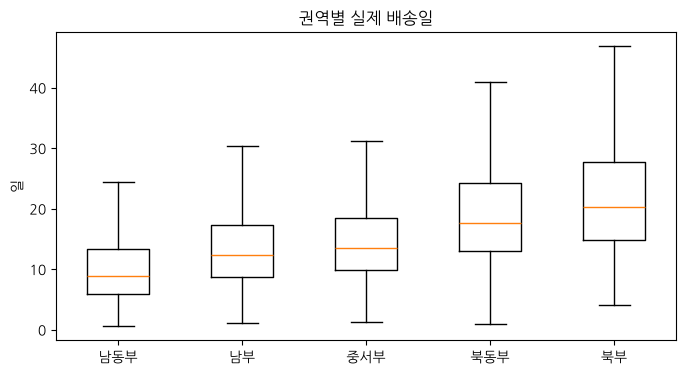

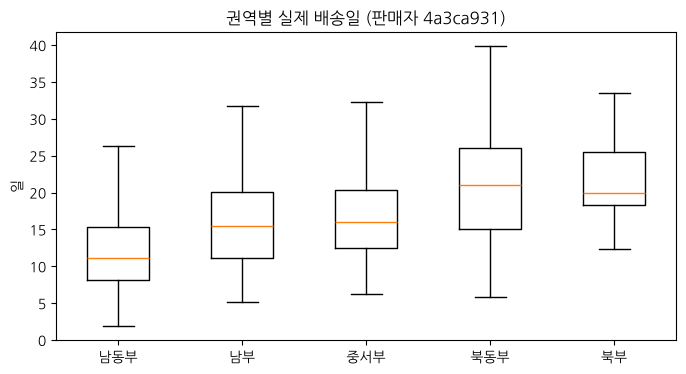

                  p25  median   p75        n
customer_region                             
남동부               5.9     8.9  13.3  62909.0
남부                8.7    12.2  17.4  13155.0
중서부               9.9    13.5  18.4   5346.0
북동부              13.0    17.6  24.2   8628.0
북부               14.8    20.3  27.7   1719.0
💬 시장 전체로 남동부는 보통 9일, 북동부는 18일, 북부는 20일 걸려요.


In [5]:
fig = st.plot('plot_region_days'); plt.show()
fig = st.plot('plot_region_days', seller_id=BIG); plt.show()
r = st.call('customer_insight', {'seller_id': BIG, 'topic': 'region_days'})
m = pd.DataFrame(r['market_days_by_region']).set_index('customer_region')
print(m.round(1))
print('💬', f"시장 전체로 남동부는 보통 {m.loc['남동부', 'median']:.0f}일, 북동부는 {m.loc['북동부', 'median']:.0f}일, 북부는 {m.loc['북부', 'median']:.0f}일 걸려요.")

## 3-5. 화난 고객은 리뷰를 빨리 쓸까?

In [6]:
r = st.call('customer_insight', {'seller_id': DEMO, 'topic': 'review_speed'})
t = pd.DataFrame(r['market_answer_speed_vs_score']).set_index('speed')
print(t)
print('💬', f"리뷰 요청에 가장 빨리 답한 25%의 1~2점 비율은 {t.low_rate.iloc[0]:.0%}로 가장 높아요. {r['advice']}")

           median_hours  mean_score  low_rate
speed                                        
가장 빠름 25%        20.578       4.022     0.169
빠름               34.169       4.271     0.099
느림               63.987       4.160     0.124
가장 느림 25%       107.794       4.147     0.125
💬 리뷰 요청에 가장 빨리 답한 25%의 1~2점 비율은 17%로 가장 높아요. 리뷰 요청 후 하루 안에 오는 리뷰가 가장 나빠요. 배송 직후에 먼저 연락해 보세요.


## 3-6. 리뷰에 날짜를 세는 고객

In [7]:
r = st.call('customer_insight', {'seller_id': DEMO, 'topic': 'said_days'})
show(r)
m = r['market']
print('💬', f"리뷰에 'N일'을 적은 고객 {m['n']}명의 평균 별점은 {m['mean_score']}점이에요 (전체 {m['overall_mean_score']}점). {r['advice']}")

{
 "topic": "said_days",
 "market": {
  "n": 512,
  "median_said": 10.0,
  "median_actual": 12.6159,
  "mean_score": 3.27,
  "overall_mean_score": 4.15
 },
 "my_count": 1,
 "my_examples": [
  {
   "order_id": "3ec53ff8dd23b7e8a90cfb4082cf3f85",
   "score": 1,
   "said_days": 50.0,
   "actual_days": 37.8698
  }
 ],
 "advice": "리뷰에 날짜를 세서 적는 고객은 불만이 큰 고객이에요. 이런 리뷰는 우선 답글을 다세요."
}
💬 리뷰에 'N일'을 적은 고객 512명의 평균 별점은 3.27점이에요 (전체 4.15점). 리뷰에 날짜를 세서 적는 고객은 불만이 큰 고객이에요. 이런 리뷰는 우선 답글을 다세요.


## 3-7. 도착 전에 쓰인 리뷰 (전처리 2판)
리뷰 요청은 약속일 무렵에 나가요. 그때까지 물건을 못 받은 고객은 **도착 전에** 리뷰를 써요.

In [8]:
r = st.call('customer_insight', {'seller_id': DEMO, 'topic': 'before_delivery'})
show(r)
mk = {row['before_delivery']: row for row in r['market']['table']}
print('💬', f"도착 전에 쓰인 리뷰는 전체의 {r['market']['share_of_reviews']:.1%}인데, 1~2점 비율이 {mk[True]['low_rate']:.0%}예요 (도착 후 리뷰 {mk[False]['low_rate']:.0%}). "
      f"내 리뷰 중에는 {r['my_before_delivery']}건({r['my_before_delivery_share']:.0%})이 도착 전에 쓰였어요. {r['advice']}")

{
 "topic": "before_delivery",
 "market": {
  "share_of_reviews": 0.053,
  "table": [
   {
    "before_delivery": false,
    "orders": 88481,
    "late_rate": 0.018,
    "low_rate": 0.096,
    "mean_score": 4.274
   },
   {
    "before_delivery": true,
    "orders": 4955,
    "late_rate": 0.955,
    "low_rate": 0.728,
    "mean_score": 1.93
   }
  ]
 },
 "my_reviews": 179,
 "my_before_delivery": 18,
 "my_before_delivery_share": 0.1006,
 "my_low_rate_before_delivery": 0.7222,
 "advice": "리뷰 요청은 약속일 무렵에 나가요. 그때까지 못 받은 고객은 도착 전에 리뷰를 쓰고, 대부분 1~2점이에요. 약속일 전에 먼저 연락하세요."
}
💬 도착 전에 쓰인 리뷰는 전체의 5.3%인데, 1~2점 비율이 73%예요 (도착 후 리뷰 10%). 내 리뷰 중에는 18건(10%)이 도착 전에 쓰였어요. 리뷰 요청은 약속일 무렵에 나가요. 그때까지 못 받은 고객은 도착 전에 리뷰를 쓰고, 대부분 1~2점이에요. 약속일 전에 먼저 연락하세요.


## 3-8. 지역 판매 기회

In [9]:
r = st.call('customer_insight', {'seller_id': BIG, 'topic': 'opportunity'})
t = pd.DataFrame(r['states']).set_index('state')
print(t.round(3))
top = t.index[0]
print('💬', f"{top}는 전체 주문의 {t.loc[top, 'market_demand_share']:.0%}인데 그 지역 판매자 비중은 {t.loc[top, 'seller_supply_share']:.0%}예요. {r['advice']}")

       market_demand_share  seller_supply_share  my_customer_share    gap
state                                                                    
RJ                   0.128                0.043              0.150  0.086
MG                   0.118                0.080              0.130  0.038
RS                   0.056                0.020              0.050  0.036
BA                   0.034                0.006              0.024  0.028
ES                   0.021                0.003              0.022  0.018
GO                   0.020                0.005              0.026  0.016
DF                   0.022                0.008              0.014  0.013
CE                   0.013                0.001              0.009  0.012
💬 RJ는 전체 주문의 13%인데 그 지역 판매자 비중은 4%예요. 수요에 비해 판매자가 적은 주(gap이 큰 주)는 경쟁이 덜한 시장이에요.
